---

Reconecte ao Drive.

In [1]:
import os
from pathlib import Path

DRIVE_DIRECTORY = Path.cwd().parent / "data"

---

In [2]:
import pickle

import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor


## Regressão polinomial

Comece recuperando os dados previsores e alvo, de treino e de teste, a partir do arquivo `parkinson.pkl` salvo na pasta do Drive. Lembre-se de que você deve instanciar as variáveis `X` e `y`, dos splits `train` e `test`,  na mesma ordem que salvou.

In [3]:
with open(os.path.join(DRIVE_DIRECTORY, 'parkinson.pkl'), 'rb') as f:
        X_treinamento, X_teste, y_treinamento, y_teste = pickle.load(f)

Instancie um transformador do tipo `PolynomialFeatures` com `degree=4`. Utilize ele para transformar os atributos previsores de treino e de teste.

In [4]:
poly = PolynomialFeatures(degree=4)
X_train_poly = poly.fit_transform(X_treinamento)
X_test_poly = poly.transform(X_teste)

Confira o `shape` dos dados previsores de treino, antes e depois de aplicar o transformador polinomial.

In [5]:
X_treinamento.shape, X_teste.shape

((4406, 19), (1469, 19))

In [6]:
X_train_poly.shape, X_test_poly.shape

((4406, 8855), (1469, 8855))

Instancie um regressor linear, e treine utilizando as variáveis preditoras polinomiais.

In [7]:
lrp = LinearRegression()
lrp.fit(X_train_poly, y_treinamento)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


Calcule o score deste regressor com os dados de treino.

In [8]:
lrp.score(X_train_poly, y_treinamento)

0.710883391100184

E também com os dados de teste.

In [9]:
lrp.score(X_test_poly, y_teste)

-9.913055902914467

Utilize o regressor para fazer predições baseadas nos dados de treinamento.

In [10]:
previsoes = lrp.predict(X_train_poly)
previsoes

array([31.82926957, 31.14542681, 23.89352344, ..., 23.37101188,
       28.67565838, 24.18303865], shape=(4406,))

Exiba o erro absoluto médio para este split.

In [11]:
mean_absolute_error(y_treinamento, previsoes)

4.345885153679631

Exiba uma comparação da variável de treino entre os valores reais e preditos, na forma de um gráfico de linhas.

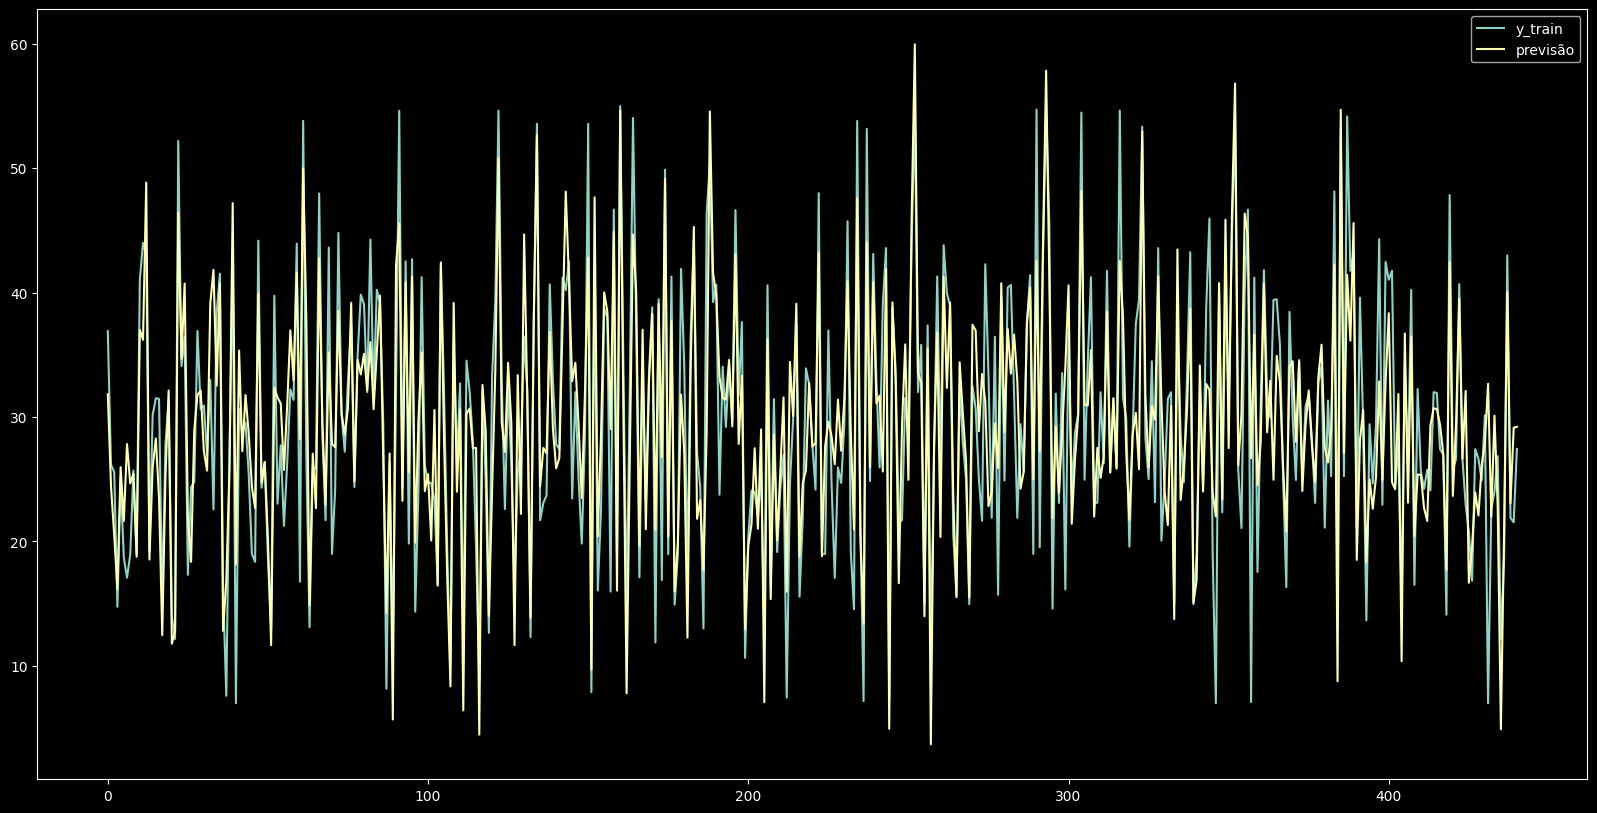

In [12]:
plt.figure(figsize=(20, 10))
plt.plot(y_treinamento[::10], label="y_train")
plt.plot(previsoes[::10], label="previsão")
plt.legend();

Tanto pelo score quanto pelo gráfico, é possível observar que, para os dados de treino, este preditor se saiu melhor do que a regressão linear múltipla da última sessão.

Agora faça predições para os dados de teste, exiba o erro absoluto médio e o gráfico de comparação.

In [14]:
previsoes = lrp.predict(X_test_poly)
previsoes

array([41.89866618, 49.41960405, 26.0968293 , ..., 41.22003857,
       28.62007928, 20.56079848], shape=(1469,))

In [15]:
mean_absolute_error(X_test_poly, previsoes)

ValueError: y_true and y_pred have different number of output (8855!=1)

In [ ]:
___

No split de teste, os resultados ficaram ainda piores do que o regressor linear, perceba que o novo regressor fez predições bastante extremas, por isso o gráfico parece achatado.

## Árvores de decisão

Instancie e treine um regressor do tipo árvore de decisão.

In [ ]:
tree = ___
___

Exiba o score deste regressor para os dados de treinamento.

In [ ]:
___

Este valor indica que as regressões ficaram perfeitas, coincidindo com os valores reais. Faça as predições para este split, exiba o erro absoluto médio e também a comparação no gráfico.

In [ ]:
___

In [ ]:
___

In [ ]:
___

O erro é aproximadamente igual a zero, e o gráfico confirma predições alinhadas com os valores reais.

Agora repita o procedimento de avaliação para o split de teste.

In [ ]:
___

In [ ]:
___

In [ ]:
___

In [ ]:
___

Como é normal, o desempenho no split de teste não ficou tão bom quanto no split de treinamento, mas ainda assim ficou excelente, com poucos valores preditos diferentes dos reais.

## RandomForest

Refaça o exercício agora utilizando um regressor do tipo Random Forest. Utilize `n_estimators=10`.

In [ ]:
rf = ___(___, random_seed=0)
___

In [ ]:
___

In [ ]:
___

In [ ]:
___

In [ ]:
___

Este regressor ficou um pouco pior que a árvore de decisão no split de treinamento, mas ainda assim muito bom!

E no split de teste?

In [ ]:
___

In [ ]:
___

In [ ]:
___

In [ ]:
___

O score ficou um pouco melhor que a árvore de decisão, apesar de o erro médio ter ficado um pouco maior. Isso indica que, em média, o erro aumentou, mas temos menos valores extremos.

## SVM

Instancie um regressor do tipo SVM, com `kernel="linear"`, e ajuste com os dados de treino.

In [ ]:
___

Exiba o score para os dados de treino e de teste.

In [ ]:
___

In [ ]:
___

Este regressor não se saiu muito bem.

Instancie e treine outro regressor do tipo SVM, mas agora com `kernel="poly"` e `degree=4`.

In [ ]:
___

Exiba os scores.

In [ ]:
___

In [ ]:
___

O resultado ficou ainda pior.

Agora vamos tentar um regressor SVM com `kernel="rbf"`. Para isso, primeiro precisamos escalonar os valores.

Instancie um escalonador para os atributos previsores, e outro para o atributo alvo, ambos do tipo `StandardScaler`.

In [ ]:
scaler_X = ___
___ = ___

Agora escalone os dados de treinamento. Lembre-se que, no caso de `y`, você deve primeiro utilizar `reshape(-1, 1)`, para apresentá-los ao escalonador no formato coluna, e depois da transformação, voltar a linearizá-lo com `ravel()`.

In [ ]:
X_train_scaled = ___.___(___)
y_train_scaled = ___.___(___.reshape(-1, 1)).___

Transforme também os dados de teste.

In [ ]:
X_test_scaled = ___.___(___)
y_test_scaled = ___.___(___).___

Agora sim instancie o regressor e ajuste com os dados escalonados.

In [ ]:
svr_rbf = ___
___

Exiba os scores do regressor.

In [ ]:
___

In [ ]:
___

Os resultados melhoraram em comparação aos outros kernels.

Utilize o regressor para fazer predições no split de teste. Depois, como esses dados estão escalonados, utilize o método `inverse_transform` do escalonador para retorná-los à escala original. Lembre-se dos cuidados com os `shape`s ao invocar o escalonador.

In [ ]:
y_pred = ___
y_pred = ___.inv___(___).___

Agora exiba o erro absoluto médio para os dados de teste em sua escala original.

In [ ]:
___

## Redes neurais artificiais

Instancie um regressor do tipo rede neural, com `max_iter=1000`. Treine este modelo com os dados escalonados.

In [ ]:
neural_net = ___
___

Exiba os scores do regressor.

In [ ]:
___

In [ ]:
___

Faça predições para os dados de teste. Lembre-se de, depois, retornar os valores preditos para sua escala original.

In [ ]:
___

Exiba o erro absoluto médio para os dados de teste.

In [ ]:
___